Anova HW\
24 Nov 2026\
Noah Runoins\
OCNG 470

In [1]:
# imports
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
#import statsmodels.api as sm
import statsmodels.formula.api as smf

from statsmodels.stats.anova import anova_lm
from statsmodels.stats.multicomp import pairwise_tukeyhsd

In [2]:
# Import data
#chl = pd.read_csv("input_data_hw470_2026.csv") # generic
chl = pd.read_csv("/home/noahr/pythonProjects/OCNG470/ANOVA_HW/input_data_hw470_2026.csv") # laptop
#chl = pd.read_csv(r"C:\Users\noahr\Documents\Python Scripts\OCNG470\ANOVA_HW\input_data_hw470_2026.csv") # desktop

chl.head()

,Sample_ID,Region,Season,Chlorophyll_mg_m3
0,CSP01,Coastal,Spring,9.45
1,CSP02,Coastal,Spring,9.90
2,CSP03,Coastal,Spring,10.05
3,CSP04,Coastal,Spring,10.25
4,CSP05,Coastal,Spring,10.75


In [3]:
# Summary statistics
summary_data = (
    chl.groupby(["Region", "Season"])["Chlorophyll_mg_m3"]
    .agg(["count", "mean", "std"])
    .reset_index()
)
summary_data

,Region,Season,count,mean,std
0,Coastal,Autumn,5,5.022,0.367587
1,Coastal,Spring,5,10.080,0.476445
2,Coastal,Summer,5,2.986,0.414403
3,Open_Ocean,Autumn,5,1.004,0.410950
4,Open_Ocean,Spring,5,1.406,0.385136
5,Open_Ocean,Summer,5,0.708,0.374326
6,Shelf,Autumn,5,3.832,0.416797
7,Shelf,Spring,5,5.506,0.380959
8,Shelf,Summer,5,2.802,0.390858


In [4]:
# Add standard error column
summary_data["stderr"] = (
    summary_data["std"] / summary_data["count"] ** 0.5
)
summary_data

,Region,Season,count,mean,std,stderr
0,Coastal,Autumn,5,5.022,0.367587,0.164390
1,Coastal,Spring,5,10.080,0.476445,0.213073
2,Coastal,Summer,5,2.986,0.414403,0.185327
3,Open_Ocean,Autumn,5,1.004,0.410950,0.183782
4,Open_Ocean,Spring,5,1.406,0.385136,0.172238
5,Open_Ocean,Summer,5,0.708,0.374326,0.167404
6,Shelf,Autumn,5,3.832,0.416797,0.186397
7,Shelf,Spring,5,5.506,0.380959,0.170370
8,Shelf,Summer,5,2.802,0.390858,0.174797


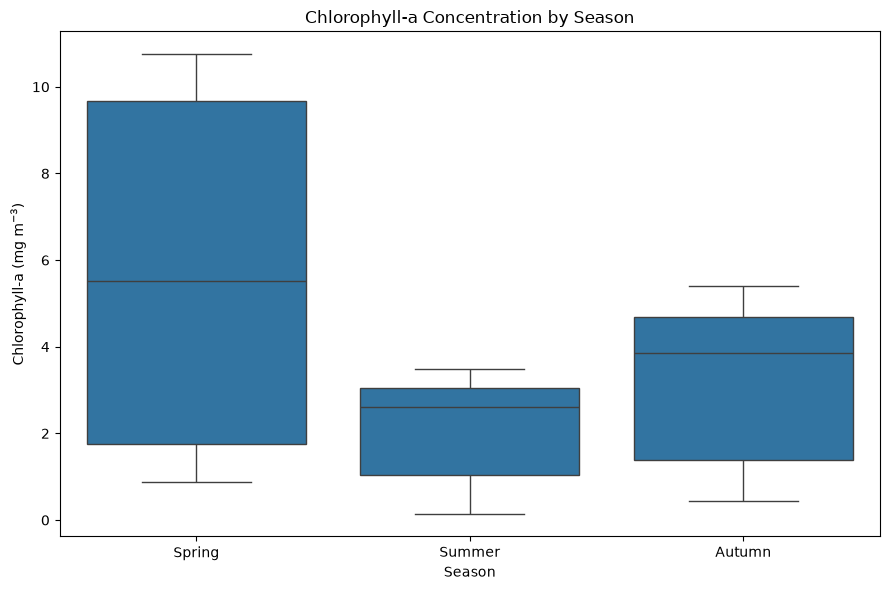

In [5]:
# Boxplot of chlorophyll-a by season
plt.figure(figsize=(9, 6))

sns.boxplot(data=chl, x="Season", y="Chlorophyll_mg_m3")

plt.xlabel("Season")
plt.ylabel("Chlorophyll-a (mg m$^{-3}$)")
plt.title("Chlorophyll-a Concentration by Season")
plt.tight_layout()
plt.show()


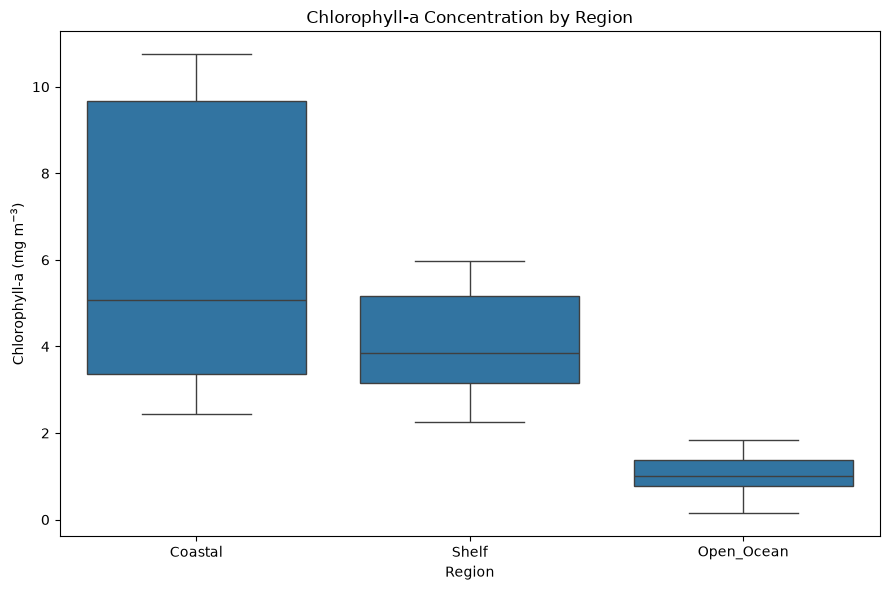

In [6]:
# Boxplot of chlorophyll-a by region
plt.figure(figsize=(9, 6))

sns.boxplot(data=chl, x="Region", y="Chlorophyll_mg_m3")

plt.xlabel("Region")
plt.ylabel("Chlorophyll-a (mg m$^{-3}$)")
plt.title("Chlorophyll-a Concentration by Region")
plt.tight_layout()
plt.show()

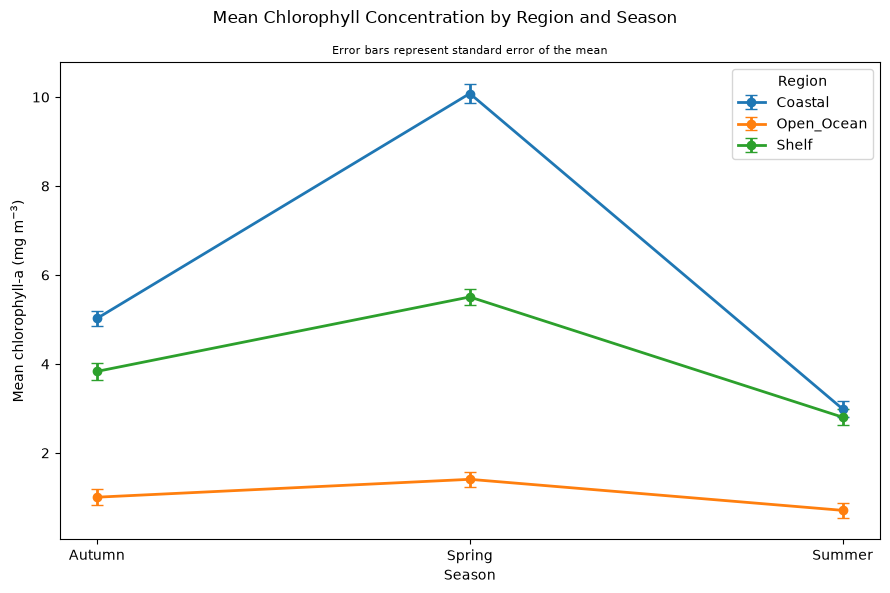

In [7]:
# Interaction plot with standard error bars
plt.figure(figsize=(9, 6))

for region, data in summary_data.groupby("Region"):
    plt.errorbar(
        data["Season"],
        data["mean"],
        yerr=data["stderr"],
        marker="o",
        capsize=4,
        linewidth=2,
        label=region
    )

plt.xlabel("Season")
plt.ylabel("Mean chlorophyll-a (mg m$^{-3}$)")
plt.suptitle("Mean Chlorophyll Concentration by Region and Season")
plt.title("Error bars represent standard error of the mean", fontsize=8)
plt.legend(title="Region")
plt.tight_layout()
plt.show()

In [8]:
# Two-way ANOVA with interaction
model = smf.ols(
    "Chlorophyll_mg_m3 ~ C(Region) * C(Season)",
    data=chl
).fit()

anova_results = anova_lm(model, typ=1)
anova_results

,df,sum_sq,mean_sq,F,PR(>F)
C(Region),2.0,189.375604,94.687802,582.574665,3.808018e-28
C(Season),2.0,95.757231,47.878616,294.577208,4.849239e-23
C(Region):C(Season),4.0,57.517289,14.379322,88.469989,4.127494e-18
Residual,36.0,5.851200,0.162533,NaN,NaN


In [9]:
# Tukey HSD comparisons
chl["Group"] = chl["Region"] + "_" + chl["Season"]

tukey = pairwise_tukeyhsd(
    endog=chl["Chlorophyll_mg_m3"],
    groups=chl["Group"],
    alpha=0.05
)

print(tukey)

            Multiple Comparison of Means - Tukey HSD, FWER=0.05            
      group1            group2      meandiff p-adj   lower    upper  reject
---------------------------------------------------------------------------
   Coastal_Autumn    Coastal_Spring    5.058    0.0   4.2173  5.8987   True
   Coastal_Autumn    Coastal_Summer   -2.036    0.0  -2.8767 -1.1953   True
   Coastal_Autumn Open_Ocean_Autumn   -4.018    0.0  -4.8587 -3.1773   True
   Coastal_Autumn Open_Ocean_Spring   -3.616    0.0  -4.4567 -2.7753   True
   Coastal_Autumn Open_Ocean_Summer   -4.314    0.0  -5.1547 -3.4733   True
   Coastal_Autumn      Shelf_Autumn    -1.19 0.0012  -2.0307 -0.3493   True
   Coastal_Autumn      Shelf_Spring    0.484 0.6192  -0.3567  1.3247  False
   Coastal_Autumn      Shelf_Summer    -2.22    0.0  -3.0607 -1.3793   True
   Coastal_Spring    Coastal_Summer   -7.094    0.0  -7.9347 -6.2533   True
   Coastal_Spring Open_Ocean_Autumn   -9.076    0.0  -9.9167 -8.2353   True
   Coastal_S